In [18]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [19]:
df = pd.read_csv("UCI_Credit_Card.csv")
df = df.rename(columns={'default.payment.next.month': 'def_pay', 'PAY_0': 'PAY_1'})

In [20]:
# Drop "ID" column.
data=df.drop(['ID'], axis=1)
print(f"There are {data.duplicated().sum()} duplicate rows in the data set.")
# Duplicate rows are removed.
df = df[~data.duplicated()]

There are 35 duplicate rows in the data set.


In [21]:
#  Marital status (1 = married; 2 = single; 3 = others).
df.MARRIAGE.value_counts()

df.loc[df.MARRIAGE == 0, 'MARRIAGE'] = 3
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64

In [22]:
# Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
df.EDUCATION.value_counts() 

fil = (df.EDUCATION == 5) | (df.EDUCATION == 6) | (df.EDUCATION == 0)
df.loc[fil, 'EDUCATION'] = 4
df.EDUCATION.value_counts()

EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

In [23]:
new_df = df.drop(columns=['BILL_AMT1', 'PAY_AMT6','def_pay','PAY_1','PAY_2'])
new_df = new_df.rename(columns={'PAY_3': 'July_Status', 
                        'PAY_4': 'June_Status',
                        'PAY_5': 'May_Status',
                        'PAY_6': 'April_Status',
                        'BILL_AMT2': 'August_Bill',
                        'BILL_AMT3': 'July_Bill',
                        'BILL_AMT4': 'June_Bill',
                        'BILL_AMT5': 'May_Bill',
                        'BILL_AMT6': 'April_Bill',
                        'PAY_AMT1': 'August_Pay',
                        'PAY_AMT2': 'July_Pay',
                        'PAY_AMT3': 'June_Pay',
                        'PAY_AMT4': 'May_Pay',
                        'PAY_AMT5': 'April_Pay'})

new_df.drop(columns=['ID'], inplace=True)

new_df['SEX'] = new_df.SEX.astype('category')
new_df['EDUCATION'] = new_df.EDUCATION.astype('category')
new_df['MARRIAGE'] = new_df.MARRIAGE.astype('category')
new_df['July_Status'] = new_df.July_Status.astype('category')
new_df['June_Status'] = new_df.June_Status.astype('category')
new_df['May_Status'] = new_df.May_Status.astype('category')
new_df['April_Status'] = new_df.April_Status.astype('category')

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
new_df["LIMIT_BAL_BIN"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Classifier

In [24]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import  f1_score

zero_new_df = new_df.copy()
# Create a binary target for zero vs non-zero payments
zero_new_df['Is_Zero'] = (zero_new_df['August_Pay'] == 0).astype(int)

# Split the data for the classification model
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(zero_new_df.drop(columns=['August_Pay', 'Is_Zero']), zero_new_df['Is_Zero'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train_class = scaler.fit_transform(X_train_class)
X_test_class = scaler.transform(X_test_class)

In [25]:
# Train the AdaBoost classifier
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train_class, y_train_class)

# Predict and evaluate the AdaBoost classifier
y_pred_ada_class = ada_model.predict(X_test_class)
ada_accuracy = f1_score(y_test_class, y_pred_ada_class)
print(f"AdaBoost F1 Score: {ada_accuracy}")

AdaBoost F1 Score: 0.7440406408753419


In [26]:
# Train the Random Forest classifier
forest_model = RandomForestClassifier(random_state=42)
forest_model.fit(X_train_class, y_train_class)

# Predict and evaluate the Random Forest classifier
y_pred_forest_class = forest_model.predict(X_test_class)
forest_accuracy = f1_score(y_test_class, y_pred_forest_class)
print(f"Random Forest F1 Score: {forest_accuracy}")

Random Forest F1 Score: 0.7890800299177263


In [27]:
# Train the MLP classifier
mlp_model = MLPClassifier(random_state=42)
mlp_model.fit(X_train_class, y_train_class)

# Predict and evaluate the MLP classifier
y_pred_mlp_class = mlp_model.predict(X_test_class)
mlp_accuracy = f1_score(y_test_class, y_pred_mlp_class)
print(f"MLP F1 Score: {mlp_accuracy}")

MLP F1 Score: 0.6548808608762491


# Regression Models

In [28]:
X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['August_Pay']), new_df['August_Pay'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)
X_test_copy = X_test.copy() # for resiuals
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Simple Features

In [29]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear_simple = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear_simple)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear_simple * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest_simple = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest_simple)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest_simple * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 15231.35735283232
Linear Regression with Classifier: 14816.874419806409
Random Forest RMSE: 15621.191405046055
Random Forest with Classifier: 15166.994047456416
MLP RMSE: 15805.346539788314
MLP with Classifier: 15469.810945343927


# Feature Transformation & New Features

In [30]:
log_new_df = new_df.copy()
log_new_df ["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["STD_PAY"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)


In [31]:
X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [32]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 14456.869063640439
Linear Regression with Classifier: 14036.972577780936
Random Forest RMSE: 15400.187889693752
Random Forest with Classifier: 14993.55185868942
MLP RMSE: 15786.053867334198
MLP with Classifier: 15241.674773475348


In [33]:
# mlp_model = MLPRegressor(random_state=42, max_iter=1000, hidden_layer_sizes=(100, 50), alpha=0.01)
# mlp_model.fit(X_train, y_train)
# y_pred_mlp = mlp_model.predict(X_test)
# print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
# print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

# Smote

In [37]:
log_new_df = new_df.copy()

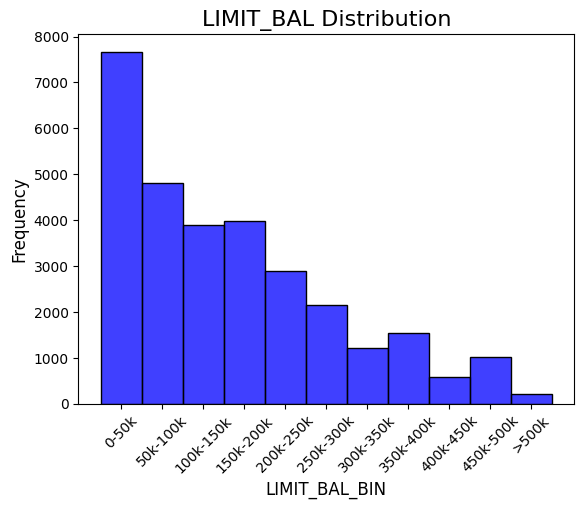

In [38]:
# Original Distribution
sns.histplot(log_new_df.LIMIT_BAL_BIN, bins=11, color="blue")
plt.title("LIMIT_BAL Distribution",fontsize=16)
plt.xlabel("LIMIT_BAL_BIN", fontsize=12)
plt.xticks(ticks=np.arange(1, 12), labels=["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"], rotation=45)
plt.ylabel("Frequency", fontsize=12)
plt.show()

In [ ]:
from imblearn.over_sampling import SMOTE

##########################################  SMOTE ##########################################

X_train_temp, X_test, _ , y_test = train_test_split(log_new_df, log_new_df['August_Pay'], test_size=0.3, stratify = new_df["LIMIT_BAL_BIN"], random_state=42)

# Drop columns
X_test.drop(columns=['August_Pay'], inplace=True)

print("Before SMOTE:")
print(X_train_temp.LIMIT_BAL_BIN.value_counts())

# Define numerical and categorical features
numerical_features = ["LIMIT_BAL", 
                      "August_Bill", "July_Bill", "June_Bill", "May_Bill", "April_Bill", 
                      "August_Pay","July_Pay", "June_Pay", "May_Pay", "April_Pay"]

categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "AGE", "July_Status", "June_Status", "May_Status", "April_Status"]
target_column = "LIMIT_BAL_BIN"

# Separate numerical and categorical data
X_numerical = X_train_temp[numerical_features]
X_categorical = X_train_temp[categorical_features]  # Store categorical data separately
y = X_train_temp[target_column]

# Apply SMOTE only on numerical features
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, _ = smote.fit_resample(X_numerical, y)

# Convert to DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=numerical_features)

# **Re-add categorical variables by sampling from original data**
X_categorical_resampled = X_categorical.sample(n=len(X_resampled_df), replace=True, random_state=42).reset_index(drop=True)

# Combine numerical, categorical, and target columns
smote_df = pd.concat([X_resampled_df, X_categorical_resampled], axis=1)

# just for checking

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
smote_df["LIMIT_BAL_BIN"] = pd.cut(smote_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Check new distribution
print("\nAfter SMOTE:")
print(smote_df[target_column].value_counts())

smote_df.drop(columns=['LIMIT_BAL_BIN'], inplace=True)

# Train-test split
y_train = smote_df.August_Pay
X_train = smote_df.drop(columns = ['August_Pay'])

cols = list(X_train.columns)
X_train = X_train[cols]
X_test = X_test[cols]


Before SMOTE:
LIMIT_BAL_BIN
1     5399
2     3401
4     2808
3     2715
5     2013
6     1485
8     1079
7      848
10     680
9      403
11     144
Name: count, dtype: int64

After SMOTE:
LIMIT_BAL_BIN
1     5399
2     5399
3     5399
4     5399
5     5399
6     5399
7     5399
8     5399
9     5399
10    5399
11    5399
Name: count, dtype: int64


# Simple Features with SMOTE

In [24]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [25]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 15946.321441963248
Linear Regression with Classifier: 15869.152402864456
Random Forest RMSE: 17014.08910897449
Random Forest with Classifier: 16999.312223832803
MLP RMSE: 16354.92851249141
MLP with Classifier: 16306.913873281937


   Bill_Range     Residuals  Percentage
0       0-50k   1993.584717        3.99
1    50k-100k   2998.728433        3.00
2   100k-150k   4007.638713        2.67
3   150k-200k   4756.412300        2.38
4   200k-250k   5272.338873        2.11
5   250k-300k   7127.368794        2.38
6   300k-350k  10595.833222        3.03
7   350k-400k   8005.188409        2.00
8   400k-450k   7951.306092        1.77
9   450k-500k  12598.167345        2.52
10      >500k  12885.955982        1.29


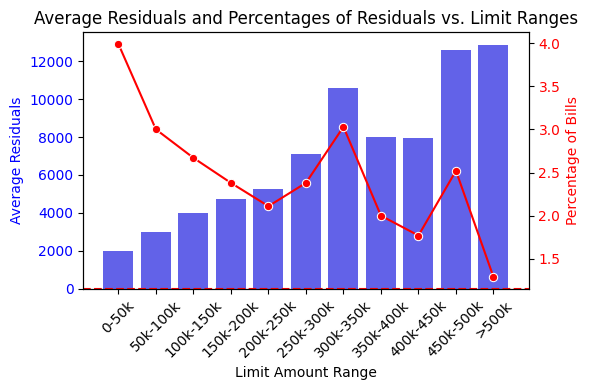

In [26]:
residuals = y_test - y_pred_linear

# Create DataFrame
temp_df = pd.DataFrame({"Limit": X_test_copy["LIMIT_BAL"], "Residuals": abs(residuals)})

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"]

# Assign bins
temp_df["Bill_Range"] = pd.cut(temp_df["Limit"], bins=bins, labels=labels, include_lowest=True)

# Compute average residuals for each bin
mean_residuals = temp_df.groupby("Bill_Range")["Residuals"].mean().reset_index()

mean_residuals['MAX'] = [50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
mean_residuals['Percentage'] = round(mean_residuals['Residuals'] / mean_residuals['MAX'] * 100, 2)
mean_residuals.drop(columns=['MAX'], inplace=True)
print(mean_residuals)


# Plot the average residuals and percentage of bills in each range on the same plot
fig, ax1 = plt.subplots(figsize=(6, 4))

# Plot average residuals
sns.barplot(x="Bill_Range", y="Residuals", data=mean_residuals, color="blue", alpha=0.7, ax=ax1)
ax1.set_xlabel("Limit Amount Range")
ax1.set_ylabel("Average Residuals", color="blue")
ax1.tick_params(axis='y', labelcolor="blue")
ax1.axhline(0, color='red', linestyle='dashed')  # Reference line at y=0
ax1.set_xticklabels(labels, rotation=45)

# Create a secondary y-axis to plot the percentage of bills
ax2 = ax1.twinx()
sns.lineplot(x="Bill_Range", y="Percentage", data=mean_residuals, color="red", marker="o", ax=ax2)
ax2.set_ylabel("Percentage of Bills", color="red")
ax2.tick_params(axis='y', labelcolor="red")

plt.title("Average Residuals and Percentages of Residuals vs. Limit Ranges")
plt.tight_layout()
plt.show()

In [27]:
# mlp_model = MLPRegressor(random_state=42, max_iter=1000, hidden_layer_sizes=(100, 50), alpha=0.01)
# mlp_model.fit(X_train, y_train)
# y_pred_mlp = mlp_model.predict(X_test)
# print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
# print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

# Feature Transformation & New Features with SMOTE

In [28]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["STD_PAY"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
log_new_df["LIMIT_BAL_BIN"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)


In [29]:

##########################################  SMOTE ##########################################

X_train_temp, X_test, _ , y_test = train_test_split(log_new_df, log_new_df['August_Pay'], test_size=0.3, random_state=42)

# Drop columns
X_test.drop(columns=['LIMIT_BAL_BIN', 'August_Pay'], inplace=True)
X_test ["LIMIT_BAL"] = np.log1p(X_test["LIMIT_BAL"]) # Log transformation

print("Before SMOTE:")
print(X_train_temp.LIMIT_BAL_BIN.value_counts())

# Define numerical and categorical features
numerical_features = ["LIMIT_BAL", 
                      "August_Bill", "July_Bill", "June_Bill", "May_Bill", "April_Bill", 
                      "August_Pay","July_Pay", "June_Pay", "May_Pay", "April_Pay"]
categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "AGE", "July_Status", "June_Status", "May_Status", "April_Status"]
target_column = "LIMIT_BAL_BIN"

# Separate numerical and categorical data
X_numerical = X_train_temp[numerical_features]
X_categorical = X_train_temp[categorical_features]  # Store categorical data separately
y = X_train_temp[target_column]

# Apply SMOTE only on numerical features
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, _ = smote.fit_resample(X_numerical, y)

# Convert to DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=numerical_features)

# **Re-add categorical variables by sampling from original data**
X_categorical_resampled = X_categorical.sample(n=len(X_resampled_df), replace=True, random_state=42).reset_index(drop=True)

# Combine numerical, categorical, and target columns
smote_df = pd.concat([X_resampled_df, X_categorical_resampled], axis=1)

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
smote_df["LIMIT_BAL_BIN"] = pd.cut(smote_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Check new distribution
print("\nAfter SMOTE:")
print(smote_df[target_column].value_counts())

smote_df.drop(columns=['LIMIT_BAL_BIN'], inplace=True)

# add features
smote_df ["LIMIT_BAL"] = np.log1p(smote_df["LIMIT_BAL"]) # Log transformation
smote_df ["AVG_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
smote_df ["AVG_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
smote_df ["MAX_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
smote_df ["MAX_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
smote_df ["MIN_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
smote_df ["MIN_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
smote_df ["PAY_SUM"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
smote_df ["BILL_SUM"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
smote_df ["CUM_PAY_JUN_JUL"] = smote_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_BILL_JUN_JUL"] = smote_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_PAY_JUN_JUL_MAY"] = smote_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_BILL_JUN_JUL_MAY"] = smote_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
smote_df ["STD_PAY"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

# Train-test split
y_train = smote_df.August_Pay
X_train = smote_df.drop(columns = ['August_Pay'])

cols = list(X_train.columns)
X_train = X_train[cols]
X_test = X_test[cols]

Before SMOTE:
LIMIT_BAL_BIN
1     5399
2     3401
4     2808
3     2715
5     2013
6     1485
8     1079
7      848
10     680
9      403
11     144
Name: count, dtype: int64

After SMOTE:
LIMIT_BAL_BIN
1     5399
2     5399
3     5399
4     5399
5     5399
6     5399
7     5399
8     5399
9     5399
10    5399
11    5399
Name: count, dtype: int64


In [30]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [31]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 15021.725509942657
Linear Regression with Classifier: 14951.949124651544
Random Forest RMSE: 17646.782403154943
Random Forest with Classifier: 17637.19999265164
MLP RMSE: 15510.167058814279
MLP with Classifier: 15461.239214290108


In [32]:
# mlp_model = MLPRegressor(random_state=42, max_iter=1000, hidden_layer_sizes=(100, 50), alpha=0.01)
# mlp_model.fit(X_train, y_train)
# y_pred_mlp = mlp_model.predict(X_test)
# print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
# print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

In [33]:
residuals = y_test - y_pred_linear * (1 - y_pred_forest_class)
residuals_simple = y_test - y_pred_linear_simple

# Create DataFrame
temp_df = pd.DataFrame({"Limit": X_test_copy["LIMIT_BAL"], "Residuals": abs(residuals), "Simple Residuals": abs(residuals_simple)})

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"]

# Assign bins
temp_df["Bill_Range"] = pd.cut(temp_df["Limit"], bins=bins, labels=labels, include_lowest=True)

# Compute average residuals for each bin
mean_residuals = temp_df.groupby("Bill_Range")["Residuals"].mean().reset_index()
mean_residuals_simple = temp_df.groupby("Bill_Range")["Simple Residuals"].mean().reset_index()
mean_residuals ['Simple Residuals'] = mean_residuals_simple['Simple Residuals'] 
mean_residuals['MAX'] = [50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
mean_residuals['Percentage'] = round(mean_residuals['Residuals'] / mean_residuals['MAX'] * 100, 2)
mean_residuals['Simple Percentage'] = round(mean_residuals['Simple Residuals'] / mean_residuals['MAX'] * 100, 2)
mean_residuals.drop(columns=['MAX'], inplace=True)
print(mean_residuals)


   Bill_Range     Residuals  Simple Residuals  Percentage  Simple Percentage
0       0-50k   1626.631088       1702.083212        3.25               3.40
1    50k-100k   2674.700209       2817.432066        2.67               2.82
2   100k-150k   3731.511611       3903.778986        2.49               2.60
3   150k-200k   4311.946818       4784.626905        2.16               2.39
4   200k-250k   4733.415145       5473.034587        1.89               2.19
5   250k-300k   6251.683340       7425.707708        2.08               2.48
6   300k-350k   8779.882230      11054.139883        2.51               3.16
7   350k-400k   7222.521345       8536.904337        1.81               2.13
8   400k-450k   7122.651704       8735.919382        1.58               1.94
9   450k-500k  12055.223843      13102.342364        2.41               2.62
10      >500k  11164.324333      14912.395009        1.12               1.49


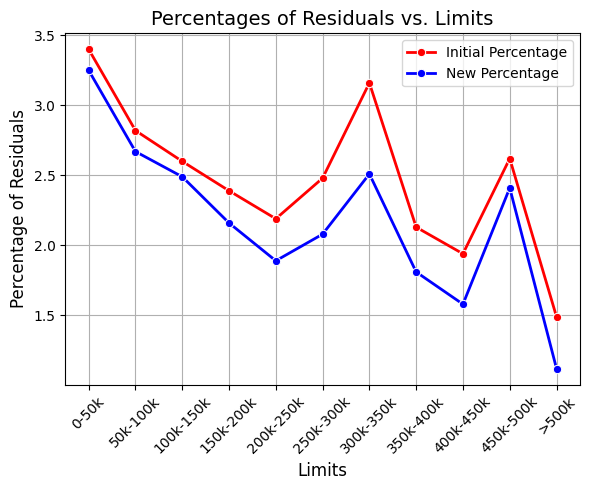

In [34]:
# Plot the average residuals and percentage of bills in each range on the same plot
fig, ax1 = plt.subplots(figsize=(6, 5))

line1 = sns.lineplot(x="Bill_Range", y="Simple Percentage", data=mean_residuals, color="red", marker="o", ax=ax1, linewidth=2, label="Initial Percentage")
line2 = sns.lineplot(x="Bill_Range", y="Percentage", data=mean_residuals, color="blue", marker="o", ax=ax1, linewidth=2, label="New Percentage")
ax1.set_ylabel("Percentage of Residuals", color="black", fontsize=12)
ax1.tick_params(axis='y', labelcolor="black")
ax1.set_xlabel("Limits", color="black", fontsize=12)
ax1.set_xticklabels(labels, rotation=45)
line1.legend(loc='upper right')
plt.title("Percentages of Residuals vs. Limits", fontsize=14)
plt.tight_layout()
plt.grid()
plt.show()



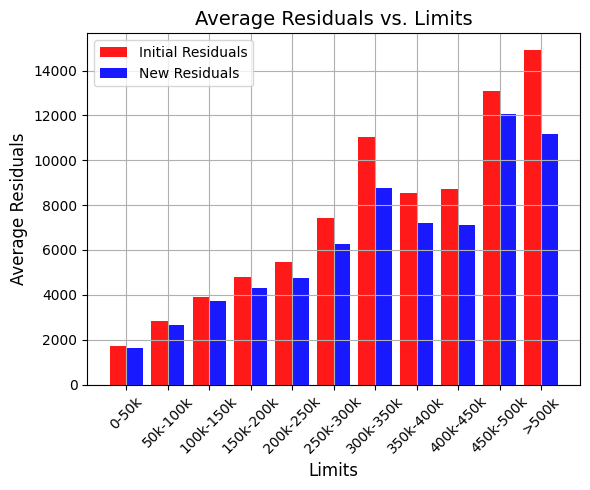

In [35]:
# Define number of bars and their x-coordinates
N = len(mean_residuals)
ind = np.arange(N)  # x locations for groups
width = 0.4 # Width of the bars

# Create figure
fig, ax = plt.subplots(figsize=(6, 5))
plt.grid()
bar1 = plt.bar(ind - width/2, mean_residuals["Simple Residuals"], width, label="Initial Residuals", color="red", alpha=0.9)
bar2 = plt.bar(ind + width/2, mean_residuals["Residuals"], width, label="New Residuals", color="blue", alpha=0.9)
plt.xlabel("Limits", fontsize=12)
plt.ylabel("Average Residuals", fontsize=12)
plt.title("Average Residuals vs. Limits", fontsize=14)
plt.xticks(ind, mean_residuals["Bill_Range"], rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
mlp_model = MLPRegressor(random_state=42, max_iter=600, hidden_layer_sizes=(50, 25), alpha=0.01)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")